# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
from pathlib import Path
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np

# Dataset: Airbnb London Listings
# Try the original course folder first, then the same folder as this notebook.
candidate_paths = [
    Path('../data/airbnb_london.csv'),
    Path('airbnb_london.csv'),
    Path('/mnt/data/airbnb_london.csv'),
]
data_file = next((path for path in candidate_paths if path.exists()), None)
if data_file is None:
    raise FileNotFoundError('Could not find airbnb_london.csv. Put it beside this notebook or in ../data/.')

df = pd.read_csv(data_file)
print(f'Loaded: {len(df):,} listings from {data_file}')
display(df.describe(include='all').round(1))

# Check that the columns required by the exercise are present.
required_columns = {'price', 'room_type', 'neighbourhood', 'reviews_per_month'}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Missing required dataset columns: {sorted(missing_columns)}')


Loaded: 2,500 listings from airbnb_london.csv


,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,reviews_per_month
count,2500,2500,2500.0,2500.0,2500.0,2500.0,2500.0
unique,10,3,NaN,NaN,NaN,NaN,NaN
top,Southwark,Entire home/apt,NaN,NaN,NaN,NaN,NaN
freq,271,1374,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,148.6,14.8,147.9,183.7,2.0
std,NaN,NaN,110.9,8.4,86.3,105.5,2.0
min,NaN,NaN,20.5,1.0,0.0,0.0,0.0
25%,NaN,NaN,71.7,8.0,74.0,92.0,0.6
50%,NaN,NaN,117.5,15.0,145.0,182.0,1.4
75%,NaN,NaN,188.9,22.0,222.2,277.0,2.8


In [2]:
# Cap price outliers at the 95th percentile for the price-distribution chart.
# This removes the top 5% of prices from the plotted data; the original df is unchanged.
p95 = df['price'].quantile(0.95)
df_cap = df.loc[df['price'] <= p95].copy()
print(f'95th percentile price cap: £{p95:.2f}')
print(f'Listings retained: {len(df_cap):,} of {len(df):,} ({len(df_cap) / len(df):.1%})')
display(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price cap: £372.66
Listings retained: 2,375 of 2,500 (95.0%)


,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,1251.0,176.3,75.7,28.0,119.6,163.4,223.5,372.6
Private room,942.0,87.3,39.5,20.9,59.0,78.6,106.0,277.9
Shared room,182.0,46.3,14.1,20.5,36.8,44.1,54.3,92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


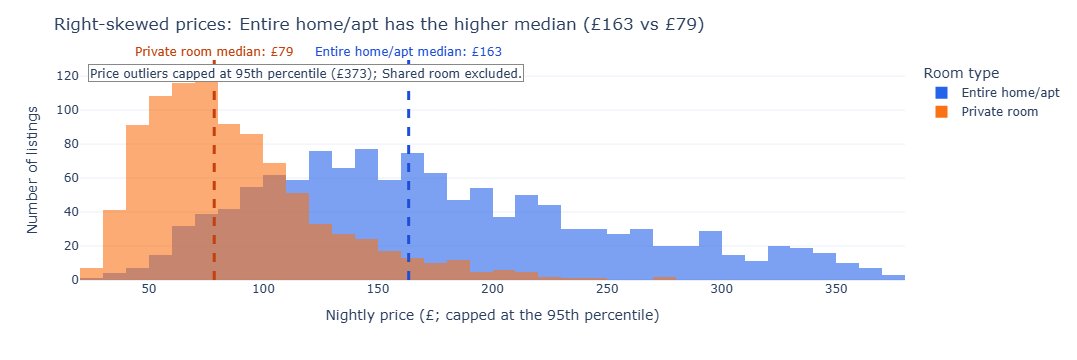

Median nightly price by room type (£):


,median_price
room_type,
Entire home/apt,163.42
Private room,78.57


Mean nightly price by room type (£):


,mean_price
room_type,
Entire home/apt,176.3
Private room,87.3


In [4]:
# Task 1 — Overlapping price histograms for Entire home/apt and Private room
room_order = ['Entire home/apt', 'Private room']
price_rooms = df_cap.loc[df_cap['room_type'].isin(room_order)].copy()

# Calculate a separate median for each room type.
room_medians = price_rooms.groupby('room_type')['price'].median()
room_means = price_rooms.groupby('room_type')['price'].mean()
higher_median_room = room_medians.idxmax()
lower_median_room = room_medians.idxmin()

fig1 = px.histogram(
    price_rooms,
    x='price',
    color='room_type',
    category_orders={'room_type': room_order},
    barmode='overlay',
    opacity=0.6,
    nbins=40,
    color_discrete_map={'Entire home/apt': '#2563eb', 'Private room': '#f97316'},
    labels={'price': 'Nightly price (£)', 'count': 'Number of listings', 'room_type': 'Room type'},
)

# Add a differently coloured vertical median line for each room type.
median_colours = {'Entire home/apt': '#1d4ed8', 'Private room': '#c2410c'}
for room in room_order:
    median_value = room_medians[room]
    fig1.add_vline(
        x=median_value,
        line_dash='dash',
        line_width=3,
        line_color=median_colours[room],
        annotation_text=f'{room} median: £{median_value:.0f}',
        annotation_position='top',
        annotation_font_color=median_colours[room],
    )

fig1.update_layout(
    title=(f'Right-skewed prices: {higher_median_room} has the higher median '
           f'(£{room_medians[higher_median_room]:.0f} vs £{room_medians[lower_median_room]:.0f})'),
    xaxis_title='Nightly price (£; capped at the 95th percentile)',
    yaxis_title='Number of listings',
    legend_title='Room type',
    template='plotly_white',
)
fig1.add_annotation(
    x=0.01, y=0.98, xref='paper', yref='paper', xanchor='left', yanchor='top',
    text=f'Price outliers capped at 95th percentile (£{p95:.0f}); Shared room excluded.',
    showarrow=False, bgcolor='white', bordercolor='#888', borderwidth=1,
)
fig1.show()

print('Median nightly price by room type (£):')
display(room_medians.rename('median_price').to_frame().round(2))
print('Mean nightly price by room type (£):')
display(room_means.rename('mean_price').to_frame().round(2))


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

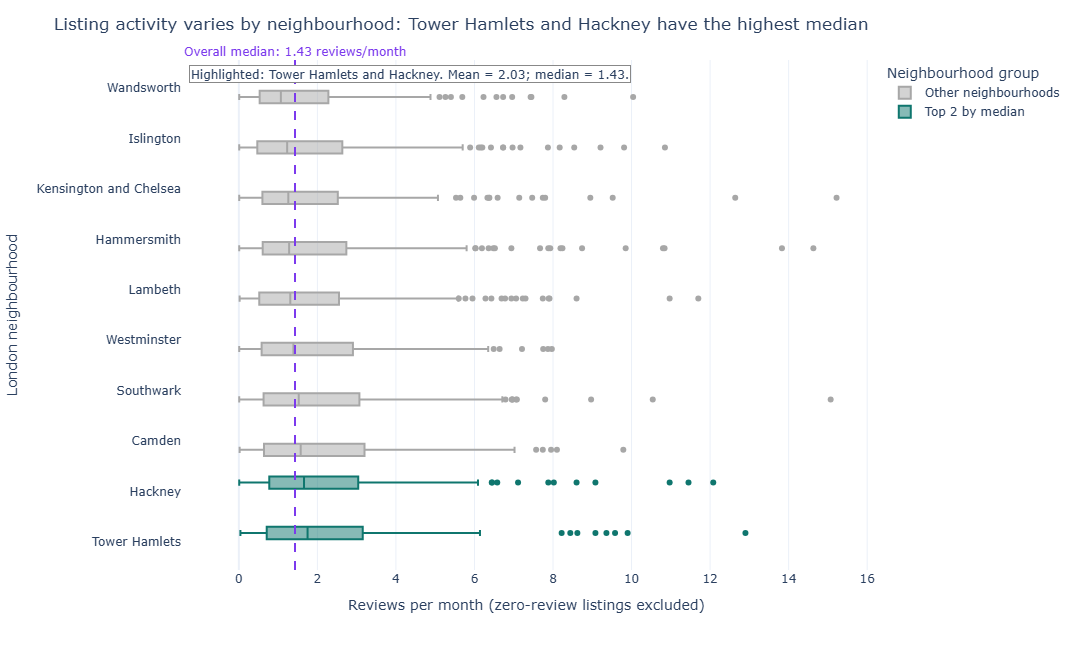

Two most active neighbourhoods by median reviews per month:


,median_reviews_per_month
neighbourhood,
Tower Hamlets,1.75
Hackney,1.66


Overall mean: 2.03; overall median: 1.43 reviews per month


In [5]:
# Task 2 — Horizontal box plot of listing activity by neighbourhood/borough
# Exclude zero-review-per-month listings as requested in the exercise.
activity = df.loc[df['reviews_per_month'].notna() & (df['reviews_per_month'] > 0),
                  ['neighbourhood', 'reviews_per_month']].copy()

# Sort neighbourhoods by median activity, with the most active at the top.
median_activity = activity.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=False)
top_two = median_activity.head(2).index.tolist()
neighbourhood_order = median_activity.sort_values(ascending=True).index.tolist()
activity['activity_group'] = np.where(activity['neighbourhood'].isin(top_two), 'Top 2 by median', 'Other neighbourhoods')

overall_median = activity['reviews_per_month'].median()
overall_mean = activity['reviews_per_month'].mean()

fig2 = px.box(
    activity,
    x='reviews_per_month',
    y='neighbourhood',
    orientation='h',
    category_orders={'neighbourhood': neighbourhood_order},
    color='activity_group',
    color_discrete_map={'Top 2 by median': '#0f766e', 'Other neighbourhoods': '#a7a7a7'},
    points='outliers',
    labels={
        'reviews_per_month': 'Reviews per month (booking-activity proxy)',
        'neighbourhood': 'London neighbourhood',
        'activity_group': 'Activity group',
    },
)

# Reference line and annotation for the overall median.
fig2.add_vline(
    x=overall_median,
    line_dash='dash',
    line_width=2,
    line_color='#7c3aed',
    annotation_text=f'Overall median: {overall_median:.2f} reviews/month',
    annotation_position='top',
    annotation_font_color='#7c3aed',
)
top_text = ' and '.join(top_two)
fig2.update_layout(
    title=f'Listing activity varies by neighbourhood: {top_text} have the highest median',
    xaxis_title='Reviews per month (zero-review listings excluded)',
    yaxis_title='London neighbourhood',
    legend_title='Neighbourhood group',
    template='plotly_white',
    height=max(650, 24 * len(neighbourhood_order) + 180),
)
fig2.add_annotation(
    x=0.01, y=0.99, xref='paper', yref='paper', xanchor='left', yanchor='top',
    text=f'Highlighted: {top_text}. Mean = {overall_mean:.2f}; median = {overall_median:.2f}.',
    showarrow=False, bgcolor='white', bordercolor='#888', borderwidth=1,
)
fig2.show()

print('Two most active neighbourhoods by median reviews per month:')
display(median_activity.head(2).rename('median_reviews_per_month').to_frame().round(2))
print(f'Overall mean: {overall_mean:.2f}; overall median: {overall_median:.2f} reviews per month')
